In [10]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import copy
from skimage.metrics import structural_similarity, mean_squared_error
print("Библиотеки загружены")

Библиотеки загружены


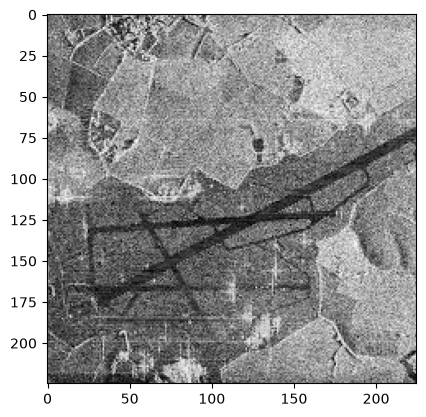

In [12]:
image = cv2.imread('sar_3.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap='gray')

Наиболее протяженный участок: длина = 237.53 пикселей


Text(0.5, 1.0, 'Наиболее протяженный участок')

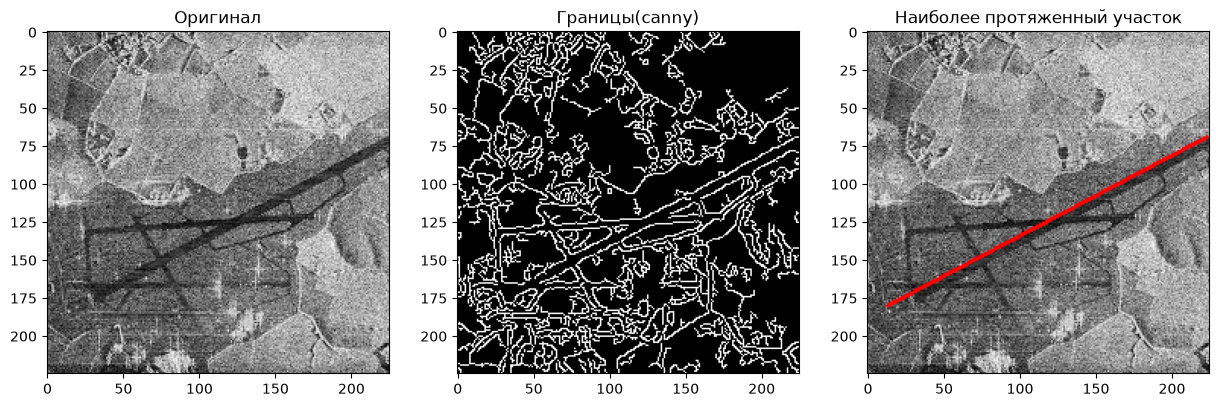

In [21]:
# 1. Найти наиболее протяженный участок (выделить линии при помощи преобразования Хафа)
blurred = cv2.GaussianBlur(image_gray, (5, 5), 0)
# Выделение границ
canny = cv2.Canny(blurred, 50, 150, apertureSize=3)

# Преобразование Хафа для поиска отрезков
lines = cv2.HoughLinesP(canny, 1, np.pi / 180, threshold=100, minLineLength=80, maxLineGap=20)

# Наиболее протяженный участок
max_len = 0
best_line = None

if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line
        length = np.sqrt((x2 - x1)**2 + (y2 - y1)**2)
        if length > max_len:
            max_len = length
            best_line = (x1, y1, x2, y2)

image_result = copy.deepcopy(image)

if best_line is not None:
    cv2.line(image_result, (best_line[0], best_line[1]), (best_line[2], best_line[3]), (0, 0, 255), 2)
    print(f"Наиболее протяженный участок: длина = {max_len:.2f} пикселей")

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image_gray, cmap='gray')
plt.title('Оригинал')

plt.subplot(1, 3, 2)
plt.imshow(canny, cmap='gray')
plt.title('Границы(canny)')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(image_result, cv2.COLOR_BGR2RGB))
plt.title('Наиболее протяженный участок')

Text(0.5, 1.0, 'Адаптивная')

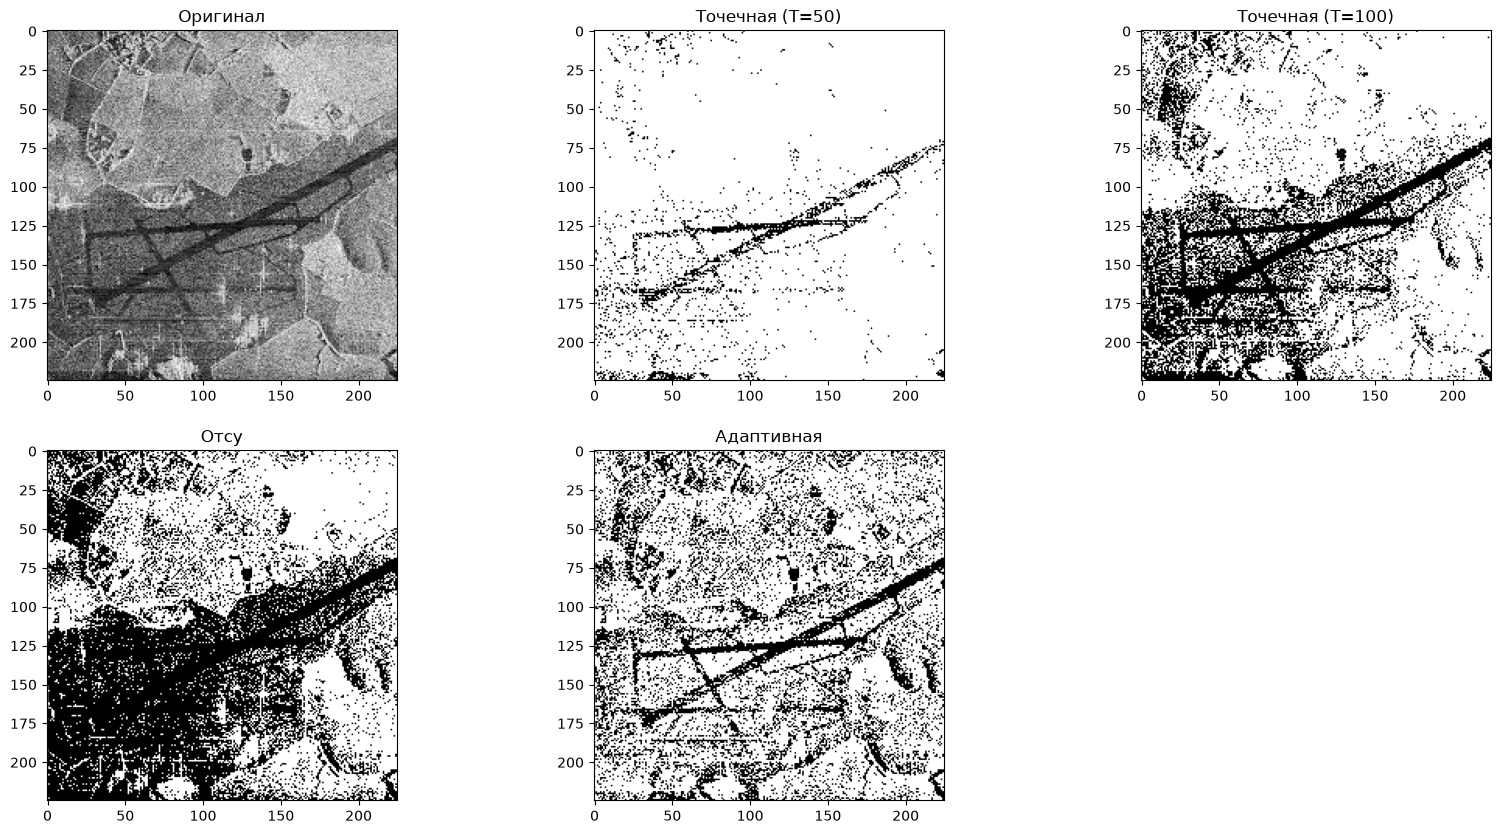

In [24]:
# 2. Для изображения sar_3.jpg провести исследование алгоритмов бинаризации, выделить участок дорожной полосы.

# Точечная бинаризация(порог=50)
bin_img_50 = copy.deepcopy(image_gray)
bin_img_50[image_gray < 50] = 0
bin_img_50[image_gray >= 50] = 255

# Точечная бинаризация(порог=100)
bin_img_100 = copy.deepcopy(image_gray)
bin_img_100[image_gray < 100] = 0
bin_img_100[image_gray >= 100] = 255

# Бинаризация Отсу
_, th_otsu = cv2.threshold(image_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Адаптивная бинаризация
th_adaptive = cv2.adaptiveThreshold(image_gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,\
                                     cv2.THRESH_BINARY, 71, 21)

plt.figure(figsize=(20, 10))

plt.subplot(2, 3, 1)
plt.imshow(image_gray, cmap='gray')
plt.title('Оригинал')

plt.subplot(2, 3, 2)
plt.imshow(bin_img_50, cmap='gray')
plt.title('Точечная (T=50)')

plt.subplot(2, 3, 3)
plt.imshow(bin_img_100, cmap='gray')
plt.title('Точечная (T=100)')

plt.subplot(2, 3, 4)
plt.imshow(th_otsu, cmap='gray')
plt.title('Отсу')

plt.subplot(2, 3, 5)
plt.imshow(th_adaptive, cmap='gray')
plt.title('Адаптивная')

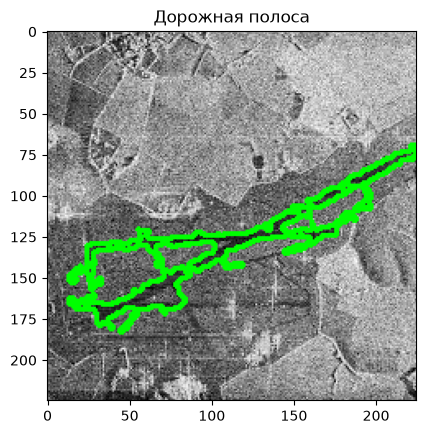

In [31]:
# Выделение участка дорожной полосы

# Ручная бинаризация(T=50)
bin_img = copy.deepcopy(image_gray)
bin_img[image_gray < 50] = 0
bin_img[image_gray >= 50] = 255

blur = cv2.GaussianBlur(bin_img, (5, 5), 0)

# Адаптивная бинаризация
thresh = cv2.adaptiveThreshold(blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,\
                                cv2.THRESH_BINARY_INV, 55, 2)

contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Отрисовка дороги зеленым
line_image = copy.deepcopy(image)
if contours:
    for contour in contours:
        area = cv2.contourArea(contour)
        if area > 500:
            cv2.drawContours(line_image, [contour], -1, (0, 255, 0), 2)
plt.imshow(cv2.cvtColor(line_image, cv2.COLOR_BGR2RGB))
plt.title('Дорожная полоса')